# LAB07 | Incertidumbre espacial y estabilidad de prioridades

**Demostración reproducible con datos sintéticos.** Este recorrido presenta los resultados de las **fases B y C**, cuyos manifiestos técnicos fueron validados. Los resultados de la fase D no se incluyen porque todavía están pendientes de la revisión integral de calidad y seguridad.

**Pregunta:** ¿una celda con alta prioridad promedio conserva esa posición cuando cambia la muestra de entrenamiento? La respuesta se describe mediante dispersión *out-of-sample* (OOS) y frecuencia de pertenencia a los conjuntos top-k, no mediante probabilidad de encontrar un yacimiento.

**Límites:** 6.300 celdas espaciales correlacionadas no son 6.300 réplicas independientes; hay solo **10 réplicas de fondo**. No se presentan intervalos inferenciales ni una precisión Monte Carlo que no haya sido demostrada. Las frecuencias top-k son **condicionales a las réplicas donde cada celda tuvo predicción OOS** y su denominador puede cambiar entre celdas. No se usa el oráculo oculto ni se interpretan los puntajes como probabilidades calibradas de depósito.

## 1. Contratos, integridad y población de análisis

Se verifican los manifiestos y los hashes SHA-256 de los archivos persistidos. El notebook no entrena un modelo nuevo ni altera los resultados científicos.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt  # noqa: E402
from IPython.display import display  # noqa: E402

RESULTS = Path("results")
PINS = {
    "score_uncertainty.csv": "7d1283dd741188ecf1d888e6442b265b247cde9ebc74bda7941409242c3dfd9a",
    "rank_stability.csv": "514bea3b479dbaa490cbb5f1733e95c08f4b663a6760589251313404c89f38a6",
    "phase_b_manifest.json": "5c231baa556843aa3cc53be622b9cfde85550773c65e7d363e992183bd66005e",
    "phase_c_manifest.json": "315a5f68a6d51f08768500a024d819461f55acd369b72a05324fb1beebd60a0e",
}
for name, expected in PINS.items():
    payload = (RESULTS / name).read_bytes()
    if name.endswith(".csv"):
        payload = payload.replace(b"\r\n", b"\n")
        assert b"\r" not in payload, f"Unsupported CSV line ending: {name}"
    actual = hashlib.sha256(payload).hexdigest()
    assert actual == expected, f"Integrity mismatch: {name}"
manifest_b = json.loads((RESULTS / "phase_b_manifest.json").read_text())
manifest_c = json.loads((RESULTS / "phase_c_manifest.json").read_text())
for manifest in (manifest_b, manifest_c):
    assert manifest["status"] == "PASS"
    assert manifest["oracle_used"] is False
    assert manifest["candidate_rows"] == 6300
    assert manifest["background_replicates"] == 10
print("CONTRACT_AND_SHA256=PASS | Fases B y C; sin oráculo")

CONTRACT_AND_SHA256=PASS | Fases B y C; sin oráculo


## 2. Unir puntajes y estabilidad por celda

La unión es uno a uno por identidad y ubicación espacial, y conserva el número de modelos OOS. No se asume independencia entre celdas.

In [2]:
score = pd.read_csv(RESULTS / "score_uncertainty.csv")
rank = pd.read_csv(RESULTS / "rank_stability.csv")
keys = ["cell_id", "Easting", "Northing", "spatial_block_id", "oos_model_count"]
assert len(score) == len(rank) == 6300
assert not score["cell_id"].duplicated().any()
assert not rank["cell_id"].duplicated().any()
data = score.merge(rank, on=keys, how="inner", validate="one_to_one")
assert len(data) == 6300
assert data["oos_model_count"].between(1, 10).all()
assert data["oos_top_5pct_frequency"].dropna().between(0, 1).all()
summary = pd.DataFrame(
    {
        "indicador": [
            "Celdas candidatas",
            "Réplicas globales",
            "Soporte OOS mínimo",
            "Soporte OOS mediano",
            "Soporte OOS máximo",
        ],
        "valor": [
            len(data),
            manifest_c["background_replicates"],
            data["oos_model_count"].min(),
            data["oos_model_count"].median(),
            data["oos_model_count"].max(),
        ],
    }
)
display(summary)
print("JOIN_AND_SUPPORT_CONTRACT=PASS")
assert data["oos_top_5pct_frequency"].notna().all()
support_9_10 = int(data["oos_model_count"].ge(9).sum())
never_top5 = int(data["oos_top_5pct_frequency"].eq(0).sum())
sometimes_top5 = int(
    data["oos_top_5pct_frequency"].between(0, 1, inclusive="neither").sum()
)
always_top5 = int(data["oos_top_5pct_frequency"].eq(1).sum())
assert never_top5 + sometimes_top5 + always_top5 == len(data)
descriptive = pd.DataFrame(
    {
        "Indicador descriptivo": [
            "Celdas con soporte OOS de 9–10 modelos",  # noqa: RUF001
            "Sin pertenencia OOS top-5%",
            "Pertenencia OOS top-5% intermitente",
            "Pertenencia OOS top-5% en todas las predicciones disponibles",
        ],
        "Celdas": [support_9_10, never_top5, sometimes_top5, always_top5],
    }
)
descriptive["Fracción de 6300 candidatas"] = descriptive["Celdas"] / len(data)
display(descriptive)
print("DESCRIPTIVE_COUNTS=PASS | Sin intervalos inferenciales")

,indicador,valor
0,Celdas candidatas,6300.0
1,Réplicas globales,10.0
2,Soporte OOS mínimo,4.0
3,Soporte OOS mediano,9.0
4,Soporte OOS máximo,10.0


JOIN_AND_SUPPORT_CONTRACT=PASS


,Indicador descriptivo,Celdas,Fracción de 6300 candidatas
0,Celdas con soporte OOS de 9–10 modelos,5091,0.808095
1,Sin pertenencia OOS top-5%,5841,0.927143
2,Pertenencia OOS top-5% intermitente,279,0.044286
3,Pertenencia OOS top-5% en todas las prediccion...,180,0.028571


DESCRIPTIVE_COUNTS=PASS | Sin intervalos inferenciales


## 3. Cobertura OOS por celda

La cantidad de modelos disponibles para cada celda condiciona cualquier estimación de estabilidad. En este estudio, el soporte OOS observado varía entre cuatro y diez modelos por celda. Las frecuencias calculadas con cuatro predicciones no son directamente comparables con las basadas en diez sin considerar sus diferentes denominadores.

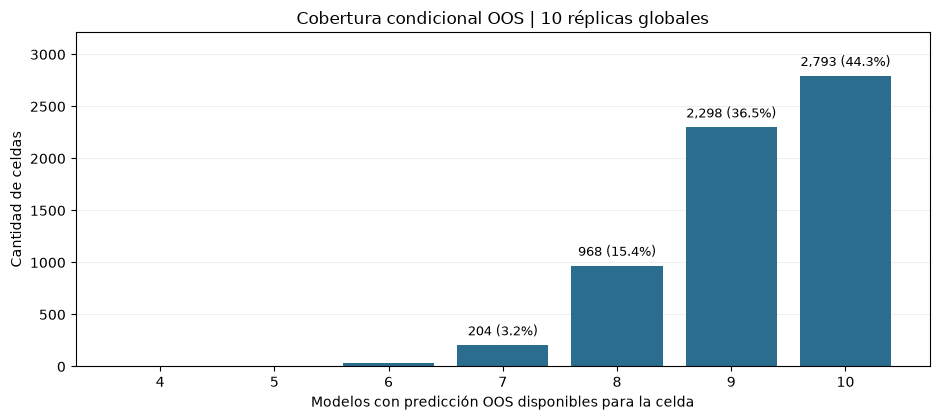

In [3]:
fig, ax = plt.subplots(figsize=(9.5, 4.3))
counts = data["oos_model_count"].value_counts().sort_index()
total = int(counts.sum())
bars = ax.bar(counts.index.astype(str), counts.values, color="#2B6D8E")
for bar, number in zip(bars, counts.values):
    if number >= 100:
        ax.annotate(
            f"{number:,} ({number / total:.1%})",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )
ax.set(
    xlabel="Modelos con predicción OOS disponibles para la celda",
    ylabel="Cantidad de celdas",
    title="Cobertura condicional OOS | 10 réplicas globales",
)
ax.set_ylim(0, max(counts.values) * 1.15)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

## 4. Mapas descriptivos: dispersión del puntaje y estabilidad top-5%

Los mapas utilizan las coordenadas `Easting`/`Northing` del experimento sintético. El identificador CRS/EPSG no se verifica en este notebook; no debe inferirse una localización geográfica exacta únicamente a partir de estos ejes. Los mapas no indican reservas minerales, certeza geológica ni probabilidades calibradas.

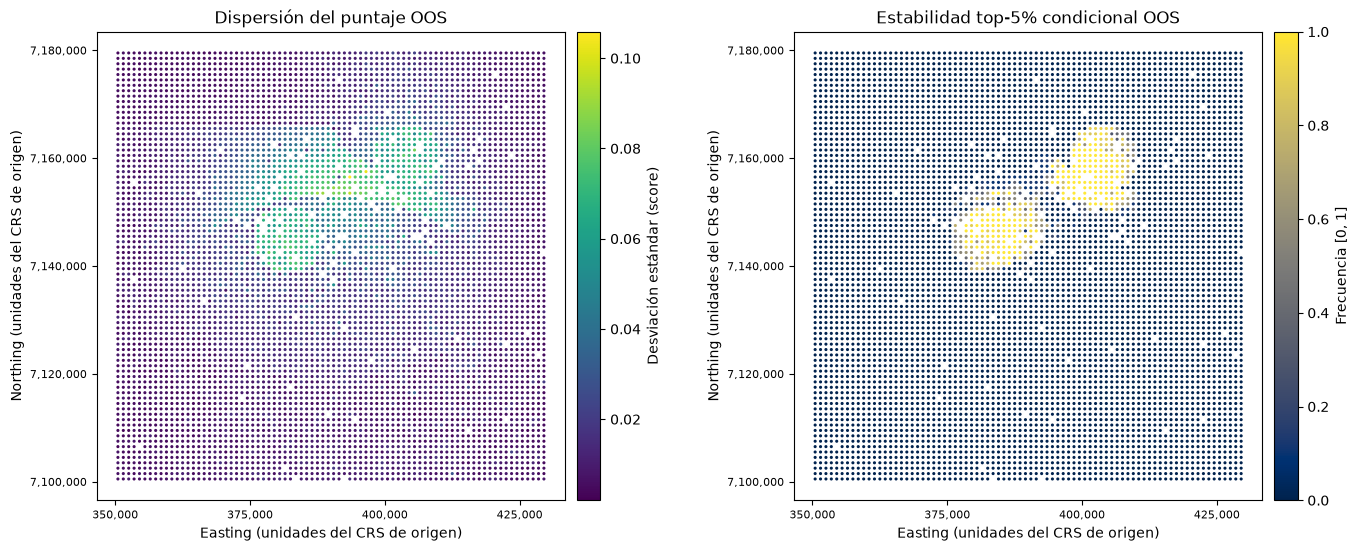

In [4]:
from matplotlib.ticker import FuncFormatter, MaxNLocator

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.4), constrained_layout=True)
plot_definitions = [
    (
        "prospectivity_score_oos_std",
        "Dispersión del puntaje OOS",
        "viridis",
        "Desviación estándar (score)",
    ),
    (
        "oos_top_5pct_frequency",
        "Estabilidad top-5% condicional OOS",
        "cividis",
        "Frecuencia [0, 1]",
    ),
]
for ax, (column, title, cmap, legend) in zip(axes, plot_definitions):
    values = pd.to_numeric(data[column], errors="coerce")
    xx = pd.to_numeric(data["Easting"], errors="coerce")
    yy = pd.to_numeric(data["Northing"], errors="coerce")
    valid = np.isfinite(values) & np.isfinite(xx) & np.isfinite(yy)
    artist = ax.scatter(
        xx.loc[valid],
        yy.loc[valid],
        c=values.loc[valid],
        s=5,
        cmap=cmap,
        linewidths=0,
        rasterized=True,
        vmin=0 if column == "oos_top_5pct_frequency" else None,
        vmax=1 if column == "oos_top_5pct_frequency" else None,
    )
    ax.set(
        title=title,
        xlabel="Easting (unidades del CRS de origen)",
        ylabel="Northing (unidades del CRS de origen)",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    fig.colorbar(artist, ax=ax, fraction=0.048, pad=0.02, label=legend)
plt.show()

## 5. Prioridad promedio versus frecuencia top-5%

La prioridad media resume el promedio de prioridades derivadas de rangos normalizados **entre las réplicas donde cada celda dispone de predicción OOS**. Los rangos se calculan dentro de cada réplica (escala 1–5.800 según el manifiesto C). No debe confundirse con el ranking agregado de 1–6.300 candidatas. Una puntuación de prioridad alta no garantiza una frecuencia top-k alta.

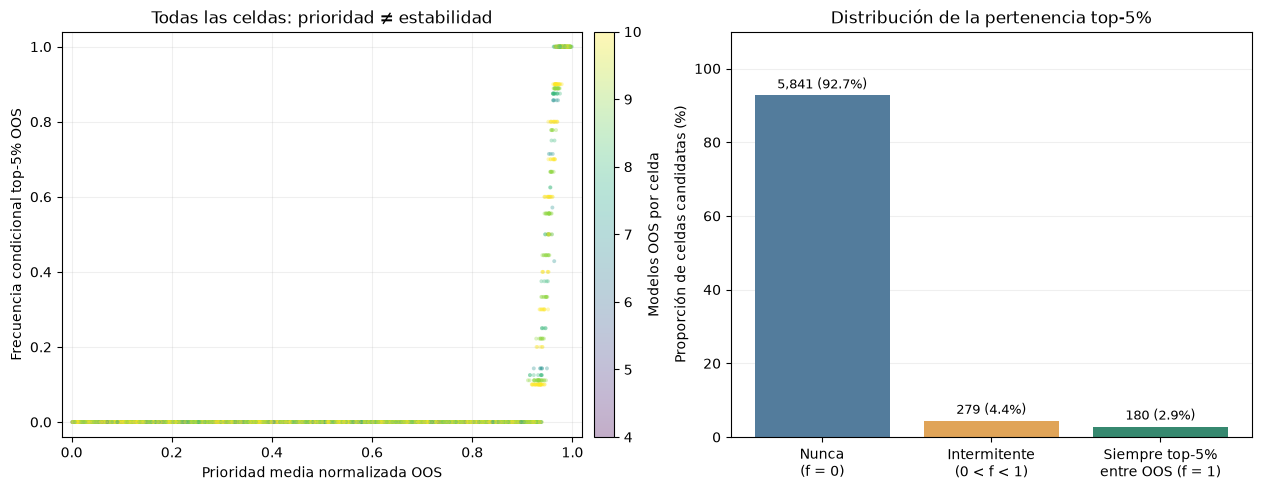

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
valid = (
    data[["oos_priority_mean", "oos_top_5pct_frequency", "oos_model_count"]]
    .notna()
    .all(axis=1)
)
artist = axes[0].scatter(
    data.loc[valid, "oos_priority_mean"],
    data.loc[valid, "oos_top_5pct_frequency"],
    c=data.loc[valid, "oos_model_count"],
    cmap="viridis",
    s=8,
    alpha=0.32,
    linewidths=0,
    rasterized=True,
    vmin=int(data["oos_model_count"].min()),
    vmax=10,
)
axes[0].set(
    title="Todas las celdas: prioridad ≠ estabilidad",
    xlabel="Prioridad media normalizada OOS",
    ylabel="Frecuencia condicional top-5% OOS",
    xlim=(-0.02, 1.02),
    ylim=(-0.04, 1.04),
)
axes[0].grid(alpha=0.2)
fig.colorbar(artist, ax=axes[0], fraction=0.05, pad=0.02, label="Modelos OOS por celda")

frequency = data["oos_top_5pct_frequency"]
category_counts = [
    int(frequency.eq(0).sum()),
    int(frequency.between(0, 1, inclusive="neither").sum()),
    int(frequency.eq(1).sum()),
]
assert sum(category_counts) == len(data)
category_names = ["Nunca\n(f = 0)", "Intermitente\n(0 < f < 1)", "Siempre top-5%\nentre OOS (f = 1)"]
shares = [100 * count / len(data) for count in category_counts]
bars = axes[1].bar(category_names, shares, color=["#537C9C", "#E0A458", "#36886F"])
for bar, count, share in zip(bars, category_counts, shares):
    axes[1].annotate(
        f"{count:,} ({share:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )
axes[1].set(
    title="Distribución de la pertenencia top-5%",
    ylabel="Proporción de celdas candidatas (%)",
    ylim=(0, 110),
)
axes[1].grid(axis="y", alpha=0.2)
axes[1].set_axisbelow(True)
plt.show()

## 6. Interpretación crítica y próximos pasos

- **Resultado mostrado:** dispersión de puntajes, soporte OOS y estabilidad relativa de prioridades bajo diez réplicas de fondo y un modelo base congelado.
- **No demostrado:** incertidumbre predictiva total, calibración probabilística, generalización a yacimientos reales, independencia espacial entre celdas o precisión inferencial de las frecuencias top-k.
- **Limitación muestral:** 6.300 filas son posiciones espaciales; no equivalen a 6.300 experimentos independientes. La adecuación de 10 réplicas necesita un análisis formal de error Monte Carlo antes de sostener inferencias fuertes.
- **Fuera del alcance:** no se presentan los resultados de la fase D (regímenes espaciales), todavía pendientes de QA, ni de la fase E, cuya ejecución no está autorizada.
- **Próxima revisión científica:** precisión Monte Carlo, estabilidad frente a cambios de diseño y límites de generalización. Una auditoría de dependencias sin vulnerabilidades conocidas no equivale a validación geológica.